# 🌌 COSMIC CENSUS LAB 01 · Exoplanet Target Selection
### Od NASA kataloga do obrazloženog predloga posmatranja
**Uvod u astrobiologiju | OAS | 2026/27 | Supervežba 1A**

> **Misija:** Vi ste član naučnog tima. Imate ograničen broj sati teleskopa. Od hiljada potvrđenih egzoplaneta treba da identifikujete **pet zanimljivih kandidata** za narednu fazu karakterizacije — i odbranite izbor.

**Trajanje:** 2 × 90 min na vežbama + samostalni rad. **Predaja:** izvršeni `.ipynb`, `top_candidates.csv`, obrazloženje od 300–500 reči.

Ovaj notebook je **originalni nastavni materijal** inspirisan zvaničnim NASA/IPAC TAP tutorijalima i pristupom korišćenim u javnim exoplanet exploration vežbama. Ne kopira tuđi notebook. NASA katalog je dinamičan: brojevi i rang-liste mogu se menjati.

## 🧭 Mapa ekspedicije
**01** Mission control → **02** Live NASA download → **03** Data integrity → **04** Detection biases → **05** Stellar physics → **06** Energy budget → **07** Monte Carlo → **08** Target selection → **09** Decision memo.

**Naučno upozorenje:** kandidat sa umerenim ozračenjem **nije automatski nastanjiv**; rang-lista meri naš izbor indikatora, a ne verovatnoću postojanja života.

In [1]:
import io, time, datetime, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plotly.express as px
from IPython.display import display, Markdown
np.random.seed(42)
pd.set_option('display.max_columns', 30)
print('✅ Environment ready |', pd.__version__, '| UTC:', datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'))

✅ Environment ready | 2.2.3 | UTC: 2026-10-23T16:51:37+00:00


## 01 · Mission control
Izaberite kriterijume. Početne granice su **nastavni scenariji**, ne univerzalne granice nastanjivosti.

- Poluprečnik ≤ 2 R⊕: mali svetovi (ne nužno stenoviti).
- Ozračenje između 0.25 i 2.0 S⊕: širok interval za demonstraciju.
- Udaljenost ≤ 100 pc: preliminarni operativni kriterijum.

Pomerite granice na kraju vežbe i posmatrajte koliko se rezultat menja.

In [2]:
CONFIG = {'radius_max':2.0, 'flux_min':0.25, 'flux_max':2.0,
          'distance_max_pc':100., 'n_mc':1500, 'seed':2026}
assert CONFIG['flux_min'] < CONFIG['flux_max']
CONFIG

{'radius_max': 2.0,
 'flux_min': 0.25,
 'flux_max': 2.0,
 'distance_max_pc': 100.0,
 'n_mc': 1500,
 'seed': 2026}

## 02 · NASA Exoplanet Archive — živi podaci
Koristimo zvanični [TAP servis](https://exoplanetarchive.ipac.caltech.edu/docs/TAP/usingTAP.html) i tabelu [`pscomppars`](https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html). Jedna planeta = jedan red, ali parametri u composite tabeli **ne moraju činiti jedinstveno samokonzistentno rešenje**. Za objavljivanje naučnih zaključaka potrebno je proveriti pojedinačne reference u `ps`.

**Uslov:** internet konekcija je obavezna za preuzimanje. Kod **ne izmišlja katalog** ako NASA servis nije dostupan.

In [3]:
BASE = 'https://exoplanetarchive.ipac.caltech.edu/TAP/sync'
COLUMNS = ['pl_name','hostname','discoverymethod','disc_year','pl_rade','pl_radeerr1','pl_radeerr2',
           'pl_bmasse','pl_orbsmax','pl_orbper','pl_insol','pl_insolerr1','pl_insolerr2',
           'st_teff','st_tefferr1','st_tefferr2','st_rad','st_raderr1','st_raderr2',
           'st_lum','sy_dist','sy_vmag','tran_flag']
ADQL = 'SELECT ' + ','.join(COLUMNS) + ' FROM pscomppars'
def nasa_tap(query=ADQL, timeout=110):
    response = requests.get(BASE, params={'query':query, 'format':'csv'}, timeout=timeout)
    response.raise_for_status()
    if 'text/html' in response.headers.get('content-type','').lower():
        raise RuntimeError('NASA returned HTML instead of CSV. Inspect the TAP query.')
    return pd.read_csv(io.StringIO(response.text))
raw = nasa_tap()
assert {'pl_name','pl_rade','st_teff'}.issubset(raw.columns)
assert len(raw)>100, 'Unexpectedly small catalog: review TAP response.'
retrieved = datetime.datetime.now(datetime.timezone.utc).isoformat()
print(f'✅ NASA LIVE: {len(raw):,} rows, {len(raw.columns)} columns; {retrieved}')
display(raw.head(3))

✅ NASA LIVE: 6,451 rows, 23 columns; 2026-10-23T16:51:46.177079+00:00


,pl_name,hostname,discoverymethod,disc_year,pl_rade,pl_radeerr1,pl_radeerr2,pl_bmasse,pl_orbsmax,pl_orbper,pl_insol,pl_insolerr1,pl_insolerr2,st_teff,st_tefferr1,st_tefferr2,st_rad,st_raderr1,st_raderr2,st_lum,sy_dist,sy_vmag,tran_flag
0,55 Cnc b,55 Cnc,Radial Velocity,1996,13.90,NaN,NaN,263.9785,0.118,14.651552,45.6336,1.9593,-1.9593,5198.0,31.0,-31.0,0.98,0.016,-0.016,-0.19695,12.5855,5.95084,0
1,55 Cnc c,55 Cnc,Radial Velocity,2004,8.51,NaN,NaN,54.4738,0.247,44.393600,10.4149,0.4349,-0.4349,5198.0,31.0,-31.0,0.98,0.016,-0.016,-0.19695,12.5855,5.95084,0
2,55 Cnc d,55 Cnc,Radial Velocity,2002,13.00,NaN,NaN,1232.4930,5.600,4799.000000,0.0203,0.0009,-0.0009,5198.0,31.0,-31.0,0.98,0.016,-0.016,-0.19695,12.5855,5.95084,0


### 🧪 Checkpoint A — može li katalog da se reprodukuje?
Proverite ponovljena imena planeta, broj praznih vrednosti i jedinstvenost naziva. Datum preuzimanja obavezno sačuvajte. Ako želite da koristite dataset na času bez mreže, sačuvajte CSV u Drive; takav snapshot je **stvaran preuzeti katalog**, a ne simulacija.

In [4]:
dup = raw['pl_name'].duplicated().sum()
quality = pd.DataFrame({'popunjeno_%':100*raw.notna().mean(), 'n_null':raw.isna().sum()}).sort_values('popunjeno_%')
print('Duplicate planet names:', dup)
display(quality)
assert dup==0, 'Unexpected duplicate names: revisit composite table semantics.'
raw.to_csv('nasa_exoplanets_snapshot.csv',index=False)
with open('snapshot_provenance.txt','w') as f:
    f.write('Source: NASA Exoplanet Archive pscomppars via TAP\nRetrieved UTC: '+retrieved+'\nADQL: '+ADQL+'\n')

Duplicate planet names: 0


,popunjeno_%,n_null
pl_radeerr1,69.400093,1974
pl_radeerr2,69.400093,1974
pl_insolerr1,73.942024,1681
pl_insolerr2,73.942024,1681
st_tefferr2,90.482096,614
st_tefferr1,90.482096,614
st_raderr2,90.590606,607
st_raderr1,90.606108,606
pl_insol,90.761122,596
pl_orbsmax,92.326771,495


## 03 · Zašto katalog nije uzorak Galaksije?
Posmatrane planete nisu slučajno odabrane. Različite metode imaju različite funkcije selekcije; grafik govori o **katalogu detekcija**, ne o intrinzičnoj raspodeli planeta u Galaksiji.

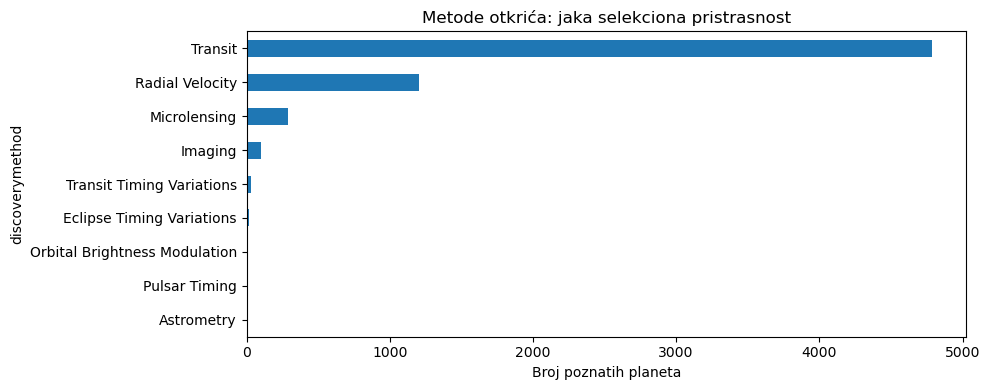

In [5]:
meth = raw['discoverymethod'].value_counts().head(9)
fig,ax=plt.subplots(figsize=(10,4))
meth.iloc[::-1].plot.barh(ax=ax)
ax.set(xlabel='Broj poznatih planeta',title='Metode otkrića: jaka selekciona pristrasnost')
plt.tight_layout();plt.show()
fig=px.scatter(raw.dropna(subset=['pl_orbper','pl_rade']).query('pl_orbper>0 and pl_rade>0'),
               x='pl_orbper',y='pl_rade',color='discoverymethod',hover_name='pl_name',
               log_x=True,log_y=True,opacity=.55,render_mode='webgl',
               labels={'pl_orbper':'Period [d]','pl_rade':'Radius [R⊕]'},
               title='Istražite opažački selection bias — zoom, hover, filter')
fig.update_layout(height=560,legend_title_text='Metod');fig.show()

**Pitanje 1 (usmeno):** Zašto je tranzitnim pregledima lakše naći kratkoperiodične planete? Zašto ne smemo iz ovih tačaka direktno zaključiti koji tip planete je najčešći u Galaksiji?

## 04 · HR dijagram + Stefan–Boltzmann
Ako imamo poluprečnik i efektivnu temperaturu zvezde, računamo

$$L_*/L_☉ = (R_*/R_☉)^2 (T_*/5772\,\mathrm{K})^4.$$

**Naučna kontrola:** arhivsko `st_lum` predstavlja **log₁₀(L/L☉)**, ne linearno L!

In [6]:
df=raw.copy()
for col in COLUMNS:
    if col not in ('pl_name','hostname','discoverymethod'):
        df[col]=pd.to_numeric(df[col],errors='coerce')
df['lum_sb']=df['st_rad']**2*(df['st_teff']/5772.)**4
df['lum_archive']=10**df['st_lum']
mask=(df['lum_sb']>0)&np.isfinite(df['lum_sb'])
fig=px.scatter(df[mask], x='st_teff',y='lum_sb',color='pl_rade',
               hover_name='pl_name',log_y=True,range_color=[0.5,6],
               labels={'st_teff':'T_eff [K]','lum_sb':'L / L☉'},title='HR-like diagram: egzoplanetne zvezde domaćini')
fig.update_xaxes(autorange='reversed');fig.show()
valid=df[['lum_sb','lum_archive']].dropna().query('lum_sb>0 and lum_archive>0')
print('Median log10 luminosity discrepancy:',np.median(np.abs(np.log10(valid.lum_sb/valid.lum_archive))) if len(valid) else 'not available')

Median log10 luminosity discrepancy: 0.028507810555853004


## 05 · Energija koju planeta prima
U aproksimaciji izotropne zvezde i kružne orbite: 

$$S/S_☉ = (L_*/L_☉)/(a/\mathrm{au})^2.$$

Ne koristimo jedan „habitability score“ bez provere. Kada je u katalogu dostupno `pl_insol`, uporedite arhivsku vrednost sa našom nezavisnom procenom. Nepodudarnosti mogu nastati usled različitih referenci i pretpostavki.

In [7]:
df['flux_calc']=df['lum_sb']/df['pl_orbsmax']**2
ok=(df['flux_calc']>0)&(df['pl_insol']>0)&np.isfinite(df['flux_calc'])
subset=df[ok].copy()
print('Planets with both flux values:',len(subset))
if len(subset):
    fig=px.scatter(subset,x='pl_insol',y='flux_calc',hover_name='pl_name',log_x=True,log_y=True,
                   labels={'pl_insol':'NASA flux [S⊕]','flux_calc':'Calculated flux [S⊕]'},title='Independent check: insolation')
    low=max(min(subset.pl_insol.min(),subset.flux_calc.min()),1e-4)
    high=min(max(subset.pl_insol.max(),subset.flux_calc.max()),1e7)
    fig.add_scatter(x=[low,high],y=[low,high],mode='lines',name='1:1')
    fig.show()
else: print('Not enough overlap: do not fabricate comparisons.')

Planets with both flux values: 5585


## 06 · Candidate funnel (not a habitability detector)
Ograničavamo se na mali poluprečnik, umereno zračenje, poznatu udaljenost i validne vrednosti. Ovo je **strategija izbora kandidata za dalju analizu**, ne dokaz nastanjivosti.

In [8]:
def funnel(data,cfg=CONFIG):
    a=data.copy()
    keep=(a['pl_rade']>0)&(a['pl_rade']<=cfg['radius_max']) & (a['pl_insol']>=cfg['flux_min']) & (a['pl_insol']<=cfg['flux_max']) & (a['sy_dist']>0)&(a['sy_dist']<=cfg['distance_max_pc'])
    return a.loc[keep].copy()
candidates=funnel(df)
print('CANDIDATES:',len(candidates),'out of',len(df))
display(candidates[['pl_name','pl_rade','pl_insol','sy_dist','st_teff']].sort_values('sy_dist').head(20))
assert (candidates['pl_rade']<=CONFIG['radius_max']).all()

CANDIDATES: 45 out of 6451


,pl_name,pl_rade,pl_insol,sy_dist,st_teff
3104,Proxima Cen d,0.692,1.8140,1.301190,2900.0
1348,Proxima Cen b,1.020,0.6410,1.301190,2900.0
1872,Ross 128 b,1.110,1.3800,3.374540,3192.0
2778,tau Cet f,1.810,0.2782,3.603040,5310.0
2792,GJ 1061 c,1.190,1.4000,3.672780,2953.0
3603,GJ 1061 d,1.160,0.6000,3.672780,2953.0
3929,Teegarden's Star b,1.050,1.0800,3.830780,3034.0
4168,Teegarden's Star c,1.020,0.3500,3.830780,3034.0
5262,Wolf 1061 c,1.660,1.3000,4.305920,3342.0
4956,GJ 1002 c,1.100,0.2570,4.848670,3024.0


### 🔬 Case studies
Istražite planete iz podataka, a ne iz ilustracija. Sledeća tri objekta su **primeri za diskusiju**; nema garancije da će zadovoljiti sve naše preseke.

In [9]:
example=['TRAPPIST-1 e','K2-18 b','GJ 1214 b']
display(df[df.pl_name.isin(example)][['pl_name','pl_rade','pl_insol','sy_dist','st_teff','pl_orbper']])

,pl_name,pl_rade,pl_insol,sy_dist,st_teff,pl_orbper
5,GJ 1214 b,2.733,17.200,14.642700,3101.0,1.580405
47,K2-18 b,2.370,1.005,38.026600,3457.0,32.939623
72,TRAPPIST-1 e,0.920,0.646,12.429889,2566.0,6.101013


## 07 · Monte Carlo: kako neizvesnosti menjaju izbor?
Ako arhiva za `pl_insol` navodi asimetrične greške, koristimo piecewise-normal uzorkovanje kao **aproksimaciju**. Ovo nije posterior iz naučnog rada, a ako greške nisu dostupne, **ne inventujemo ih**.

Dobijena vrednost `P(in window)` predstavlja verovatnoću uslovljenu modelom grešaka i *našim numeričkim granicama*, ne verovatnoću života.

In [10]:
def draw_asym(mu,eplus,eminus,n=1500,rng=None):
    rng=np.random.default_rng() if rng is None else rng
    z=rng.standard_normal(n)
    return mu + np.where(z>=0,abs(eplus)*z,abs(eminus)*z)
def probability_in_flux_window(row,cfg=CONFIG):
    cols=['pl_insol','pl_insolerr1','pl_insolerr2']
    if not np.all(pd.notna([row.get(c,np.nan) for c in cols])): return np.nan
    mu,hi,lo=[float(row[c]) for c in cols]
    if mu<=0 or hi<=0 or lo>=0: return np.nan
    rng=np.random.default_rng(cfg['seed'])
    x=draw_asym(mu,hi,lo,cfg['n_mc'],rng)
    return ((x>=cfg['flux_min'])&(x<=cfg['flux_max'])).mean()
if len(candidates):
    candidates['p_flux_window']=candidates.apply(probability_in_flux_window,axis=1)
    display(candidates[['pl_name','pl_insol','pl_insolerr1','pl_insolerr2','p_flux_window']].head(12))
    print('MC coverage:',candidates.p_flux_window.notna().sum(),'/',len(candidates))

,pl_name,pl_insol,pl_insolerr1,pl_insolerr2,p_flux_window
58,TRAPPIST-1 d,1.1150,0.0430,-0.0430,1.000000
72,TRAPPIST-1 e,0.6460,0.0250,-0.0250,1.000000
73,TRAPPIST-1 f,0.3730,0.0150,-0.0140,1.000000
74,TRAPPIST-1 g,0.2520,0.0100,-0.0100,0.582000
78,LHS 1140 b,0.4300,0.0300,-0.0300,1.000000
143,TOI-700 d,0.8500,0.0900,-0.1000,1.000000
208,TOI-700 e,1.2700,0.1300,-0.1500,1.000000
248,LP 890-9 c,0.9060,0.0260,-0.0260,1.000000
283,L 98-59 f,1.1000,0.1100,-0.1100,1.000000
877,GJ 667 C f,0.5633,0.1181,-0.1181,0.994000


MC coverage: 41 / 45


## 08 · Transparent target-ranking: no magical index
Operativno rangiranje koristi **dva deklarisana** kriterijuma: blizinu i manji radijus. Ozračenje je već tretirano kao uslov preseka. Ne nazivamo ga „habitability probability“. Nedostajuće vrednosti su isključene iz ovog rangiranja.

In [11]:
def rank_targets(data,dist_weight=.60):
    a=data.dropna(subset=['sy_dist','pl_rade']).copy()
    if a.empty:return a
    near = 1/(1+a.sy_dist/20)
    small = 1/(1+a.pl_rade/1.5)
    a['priority_score']=dist_weight*near+(1-dist_weight)*small
    return a.sort_values(['priority_score','pl_name'],ascending=[False,True])
ranked=rank_targets(candidates)
display(ranked[['pl_name','sy_dist','pl_rade','pl_insol','priority_score']].head(10))
if len(ranked):
    fig=px.scatter(ranked.head(100),x='sy_dist',y='pl_insol',size='pl_rade',
                   color='priority_score',hover_name='pl_name',
                   labels={'sy_dist':'Distance [pc]','pl_insol':'Flux [S⊕]'},
                   title='Interaktivna mapa kandidata — boja = operativni prioritet')
    fig.show()
ranked.head(10).to_csv('top_candidates.csv',index=False)

,pl_name,sy_dist,pl_rade,pl_insol,priority_score
3104,Proxima Cen d,1.30119,0.692,1.8140,0.837071
1348,Proxima Cen b,1.30119,1.020,0.6410,0.801444
1872,Ross 128 b,3.37454,1.110,1.3800,0.743264
4168,Teegarden's Star c,3.83078,1.020,0.3500,0.741646
3929,Teegarden's Star b,3.83078,1.050,1.0800,0.738845
3603,GJ 1061 d,3.67278,1.160,0.6000,0.732475
2792,GJ 1061 c,3.67278,1.190,1.4000,0.729960
3479,GJ 1002 b,4.84867,1.030,0.6700,0.720077
4956,GJ 1002 c,4.84867,1.100,0.2570,0.713692
2778,tau Cet f,3.60304,1.810,0.2782,0.689678


## 09 · Sensitivity lab: koliko je rang stabilan?
Ponavljamo postupak za različite težine. Ako se objekat pojavljuje samo za jednu arbitrarno izabranu težinu, to treba jasno reći.

,distance_weight,n_top10,overlap_with_0.6
0,0.2,10,8
1,0.4,10,9
2,0.6,10,10
3,0.8,10,10


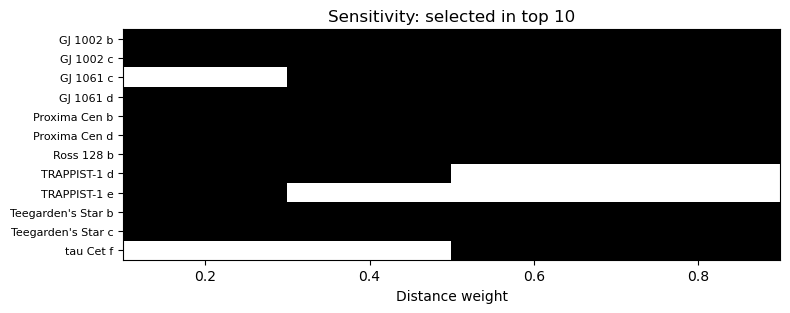

In [12]:
weights=[0.2,0.4,0.6,0.8]
sets={w:set(rank_targets(candidates,w).head(10).pl_name) for w in weights}
rows=[]
for w in weights:
    rows.append({'distance_weight':w,'n_top10':len(sets[w]),'overlap_with_0.6':len(sets[w]&sets[0.6])})
display(pd.DataFrame(rows))
if len(candidates):
    ordered=sorted(set.union(*sets.values())) if sets else []
    heat=pd.DataFrame({str(w):[int(name in sets[w]) for name in ordered] for w in weights},index=ordered)
    if len(heat):
        fig,ax=plt.subplots(figsize=(8,max(3,len(heat)*.27)))
        ax.imshow(heat.values,aspect='auto',vmin=0,vmax=1,cmap='Greys')
        ax.set_yticks(range(len(heat)),ordered,fontsize=8)
        ax.set_xticks(range(len(weights)),[str(w) for w in weights]);ax.set_xlabel('Distance weight')
        ax.set_title('Sensitivity: selected in top 10');plt.tight_layout();plt.show()

## 10 · Research challenge — obavezni samostalni rad (8 poena)
**A (2 poena):** Navedite tri izvora selekcione pristrasnosti i objasnite njihov uticaj na kandidat-listu.

**B (2 poena):** Izaberite alternativni interval ozračenja; ponovite izbor i kvantifikujte promenu broja kandidata.

**C (2 poena):** Objasnite dve fizičke degeneracije koje naša rang-lista ignoriše (atmosfera, masa/g, aktivnost zvezde, oblaci, itd.).

**D (2 poena):** Napišite *telescope allocation memo* (300–500 reči): navedite pet kandidata, jasne kriterijume, ključne neizvesnosti i sledeće opažanje koje biste zatražili.

**Poželjno za napredne:** Izaberite jedan kandidat i pogledajte njegove referencirane parametre u tabeli `ps`; objasnite zašto se published solutions razlikuju.

In [13]:
# STUDENT WORKSPACE
# 1. Change the flux criteria and report selection sensitivity.
# 2. Make at least one new diagnostic plot.
# 3. Save the revised selection as CSV.
# YOUR CODE HERE

## 📚 Izvori i naučna etika
- [NASA Exoplanet Archive — TAP](https://exoplanetarchive.ipac.caltech.edu/docs/TAP/usingTAP.html)
- [NASA `ps` / `pscomppars` columns and caveats](https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html)
- [Exoplanet Archive documentation](https://exoplanetarchive.ipac.caltech.edu/)
- Za atribuciju podataka koristiti DOI/citation preporuku same NASA arhive.
- Originalni nastavni modul; inspirisan javnim NASA/IPAC tutorijalima, a ne njihova reprodukcija.
- Navedite sve korišćene spoljne kodove i generativne alate.

---
# 🔐 DODATAK ZA ASISTENTA — rešenja, nastavna dramaturgija i očekivanja
**Ne distribuirati studentima.** Tokom časa insistirati na razlici između *populacije otkrivenih objekata*, *naučno zanimljivih objekata* i *dokazane nastanjivosti*.

**Raspored:** 15 min scenario i TAP; 25 min completeness i bias; 25 min HR i ozračenje; 25 min prvi filter; druga sesija 35 min Monte Carlo, 30 min sensitivity, 25 min debate/memo.

**Nema fiksnog očekivanog broja planeta:** arhiva se stalno dopunjuje. Ako je NASA servis nedostupan, koristiti ranije sačuvan **autentični snapshot**, uz vidljiv datum i poreklo; ne praviti veštački katalog.

**Kontrolne vrednosti:** Sunce sa T=5772 K, R=1 R☉ ima L≈1 L☉; planeta na 1 au prima S≈1 S⊕. Kada je dostupno `st_lum`, pretvaranje je 10**st_lum.

**Ocena:** A 2 = prepoznata tri konkretna bias-a; B 2 = reproduktibilan novi filter + brojčano poređenje; C 2 = dve naučno tačne degeneracije; D 2 = opravdani izbor pet meta i dalja strategija.

**Tipične greške:** upotreba `st_lum` kao linearne veličine; naziv `P(life)` za Monte Carlo rezultat; mešanje katalogizovanih i svih postojećih planeta; tvrdnja da R<2 R⊕ znači stenovitost; ignorisanje promenljive upotpunjenosti.


In [14]:
# Teacher reference: alternative selection scenario (different from default)
alternative={**CONFIG,'flux_min':0.5,'flux_max':1.5}
alt=funnel(df,alternative)
base_names=set(candidates.pl_name); alt_names=set(alt.pl_name)
print('Default:',len(base_names),'Alternative:',len(alt_names))
print('Retained:',len(base_names & alt_names),'Dropped:',len(base_names-alt_names),'Added:',len(alt_names-base_names))
assert alt_names.issubset(base_names), 'Narrower flux interval should be a subset.'


Default: 45 Alternative: 25
Retained: 25 Dropped: 20 Added: 0
